# How to Build the Doom Scroll: companion notebook

HON 4013 · AI, Finance, and Human Futures · Dr. Jesse Roberts · Fall 2026

This notebook reproduces every computed number and animation on the lecture's slides: the grid world that learns from rewards, the slot-machine (bandit) experiments, the ad auction, and the toy feed that learns to keep a simulated user scrolling. It needs only Python, NumPy and matplotlib, runs on a CPU, and takes about two minutes.

Numbers quoted from outside sources (X's 2023 ranking weights, Meta's earnings calls, the ShareChat and YouTube papers) and the illustrative values on some slides (the insurance points, the embedding maps, the 200 ms time budget) are not computed here.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, INK, GREY = "#2557D6", "#C2510F", "#16181D", "#8E94A0"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## Learning from rewards · Rewards that arrive later

A 5 × 5 grid world. Every move costs 1, the goal pays +10, the pit costs −10, and grey squares are walls (bumping one leaves you in place). The agent learns with **Q-learning**: it keeps an estimate Q(state, action) of the total future reward of each move and nudges it toward *reward now + 0.9 × best estimate from the next square*. Early episodes are almost all random moves (exploring); the share of random moves falls to 10%.

In [2]:
ROWS, COLS = 5, 5
START, GOAL, PIT = (4, 0), (0, 4), (1, 3)
WALLS = {(1, 1), (2, 1), (3, 3), (2, 3)}
STEP_REWARD, GOAL_REWARD, PIT_REWARD = -1.0, 10.0, -10.0
GAMMA, ALPHA, EPISODES = 0.9, 0.5, 100
MOVES = [(-1, 0), (0, 1), (1, 0), (0, -1)]          # up, right, down, left
ARROWS = ["↑", "→", "↓", "←"]


def step(state, action):
    """Apply one move; return (next state, reward, episode over?)."""
    r, c = state[0] + MOVES[action][0], state[1] + MOVES[action][1]
    if not (0 <= r < ROWS and 0 <= c < COLS) or (r, c) in WALLS:
        r, c = state                                    # bumped a wall or the edge: stay put
    if (r, c) == GOAL:
        return (r, c), GOAL_REWARD, True
    if (r, c) == PIT:
        return (r, c), PIT_REWARD, True
    return (r, c), STEP_REWARD, False


def explore_rate(episode):
    """Share of random moves: 100% in episode 1, falling 2 points per episode to a floor of 10%."""
    return max(0.1, 1.0 - episode / 50)

In [3]:
random.seed(32)
Q = {(r, c): [0.0] * 4 for r in range(ROWS) for c in range(COLS)}
episode_returns, episode_lengths, outcomes = [], [], []

for episode in range(EPISODES):
    state, total = START, 0.0
    for t in range(10_000):                             # no practical cap: every episode ends at the goal or the pit
        if random.random() < explore_rate(episode):
            action = random.randrange(4)               # explore
        else:
            action = Q[state].index(max(Q[state]))     # exploit the current best guess
        next_state, reward, done = step(state, action)
        total += reward
        target = reward if done else reward + GAMMA * max(Q[next_state])
        Q[state][action] += ALPHA * (target - Q[state][action])
        state = next_state
        if done:
            break
    episode_returns.append(total)
    episode_lengths.append(t + 1)
    outcomes.append("goal" if state == GOAL else "pit")

print("Episodes 1-3:", list(zip(episode_lengths[:3], outcomes[:3])))
print("Explore rate by episode 1, 23, 40, 59:", [f"{explore_rate(e - 1):.0%}" for e in (1, 23, 40, 59)])

Episodes 1-3: [(41, 'pit'), (32, 'goal'), (58, 'pit')]
Explore rate by episode 1, 23, 40, 59: ['100%', '56%', '22%', '10%']


Episode 1 wanders for 41 random moves and falls in the pit; episode 2 stumbles onto the goal after 32 (the slide's opening). The total reward per episode climbs as the agent learns:

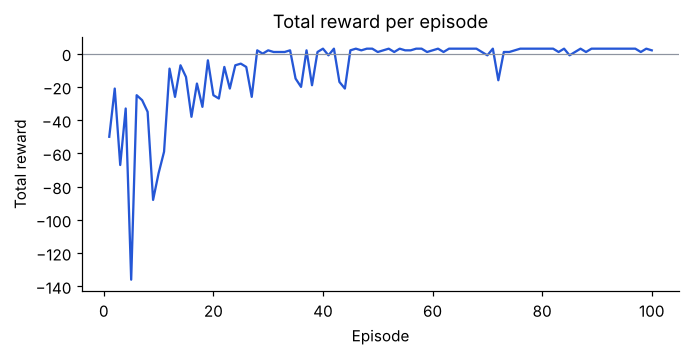

In [4]:
plt.figure(figsize=(7, 3))
plt.plot(range(1, EPISODES + 1), episode_returns, color=BLUE)
plt.axhline(0, color=GREY, linewidth=0.8)
plt.title("Total reward per episode")
plt.xlabel("Episode")
plt.ylabel("Total reward")
plt.show()

The learned values (the number beside each arrow on the slide) and the best move in each square. Following the best moves from S traces the 8-move route, and walking back from the goal shows the +10 shrinking one step at a time (×0.9, then −1 for the move): the chain on *Rewards that arrive later*.

In [5]:
def best_route(Q, start=START, max_steps=20):
    """Follow the highest-valued move from the start until the episode ends."""
    route, state = [start], start
    for _ in range(max_steps):
        state, _, done = step(state, Q[state].index(max(Q[state])))
        route.append(state)
        if done:
            break
    return route


route = best_route(Q)
print("Route:", " ".join(ARROWS[MOVES.index((b[0] - a[0], b[1] - a[1]))] for a, b in zip(route, route[1:])))
values_back_from_goal = [max(Q[s]) for s in route[:-1]][::-1]
print("Values walking back from the goal:", " → ".join(f"{v:.1f}" for v in values_back_from_goal))

print("\nValue of each move (up, right, down, left) in the start square:", [round(q, 1) for q in Q[START]])

Route: → → ↑ ↑ ↑ ↑ → →
Values walking back from the goal: 10.0 → 8.0 → 6.2 → 4.6 → 3.1 → 1.8 → 0.6 → -0.4

Value of each move (up, right, down, left) in the start square: [-4.1, -0.4, -2.0, -1.9]


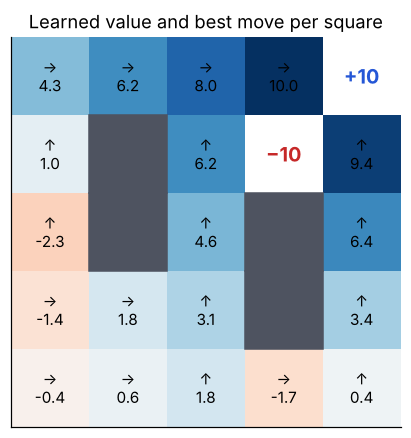

In [6]:
values = np.full((ROWS, COLS), np.nan)
for (r, c), q in Q.items():
    if (r, c) not in WALLS and (r, c) not in (GOAL, PIT):
        values[r, c] = max(q)

fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.imshow(values, cmap="RdBu", vmin=-10, vmax=10)
for (r, c), q in Q.items():
    if (r, c) in WALLS:
        ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, color="#4E5360"))
    elif (r, c) == GOAL:
        ax.text(c, r, "+10", ha="center", va="center", color=BLUE, fontsize=13, weight="bold")
    elif (r, c) == PIT:
        ax.text(c, r, "−10", ha="center", va="center", color="#C62828", fontsize=13, weight="bold")
    else:
        ax.text(c, r, f"{ARROWS[q.index(max(q))]}\n{max(q):.1f}", ha="center", va="center", fontsize=10)
ax.set_xticks([])
ax.set_yticks([])
ax.set_title("Learned value and best move per square")
plt.show()

## Explore or exploit?

Three slot machines pay 30%, 50% and 70% of the time; the player doesn't know which is which. **Greedy** tries each machine once and then always plays the best so far. **ε-greedy** does the same but picks a random machine 10% of the time.

First the slide's two players. Each machine's run of wins and losses is fixed in advance, so both players get exactly the same luck and only the strategy differs.

In [7]:
PAYOUT = [0.30, 0.50, 0.70]
PULLS, EPSILON = 200, 0.1


def play(epsilon, rng, outcomes=None):
    """Play 200 pulls; return (pulls per machine, wins per machine). `outcomes` fixes each machine's luck."""
    pulls, wins = [0, 0, 0], [0, 0, 0]
    for t in range(PULLS):
        if t < 3:
            arm = t                                     # try each machine once
        elif rng.random() < epsilon:
            arm = rng.randrange(3)                      # explore
        else:
            win_rates = [wins[i] / pulls[i] for i in range(3)]
            arm = win_rates.index(max(win_rates))       # exploit
        if outcomes is not None:
            reward = outcomes[arm][pulls[arm]]
        else:
            reward = 1 if rng.random() < PAYOUT[arm] else 0
        pulls[arm] += 1
        wins[arm] += reward
    return pulls, wins


SEED = 13                                               # a game where the best machine loses its first pull
luck_rng = random.Random(SEED)
luck = [[1 if luck_rng.random() < p else 0 for _ in range(PULLS)] for p in PAYOUT]
for name, eps in (("Try all, then best so far", 0.0), ("Explore 10% of the time", EPSILON)):
    pulls, wins = play(eps, random.Random(SEED * 1000 + 1), outcomes=luck)
    print(f"{name:26s} pulls {pulls}  wins {wins}  total {sum(wins)}")

Try all, then best so far  pulls [198, 1, 1]  wins [71, 0, 0]  total 71
Explore 10% of the time    pulls [43, 7, 150]  wins [14, 1, 105]  total 120


Machine A happens to win its first pull while B and C lose theirs, so the greedy player never returns to C. Now the averages the slide reveals on click, over 2,000 independent games:

In [8]:
rng = random.Random(7)
results = {}
for name, eps in (("greedy", 0.0), ("explore 10%", EPSILON)):
    total_wins, share_on_best = 0, 0.0
    for _ in range(2000):
        pulls, wins = play(eps, rng)
        total_wins += sum(wins)
        share_on_best += pulls[2] / PULLS
    results[name] = (total_wins / 2000, share_on_best / 2000)
    print(f"{name:12s} average wins {total_wins / 2000:.1f}   best machine {share_on_best / 2000:.0%} of pulls")
print("Best possible:", PULLS * max(PAYOUT))

greedy       average wins 118.7   best machine 63% of pulls


explore 10%  average wins 127.5   best machine 76% of pulls
Best possible: 140.0


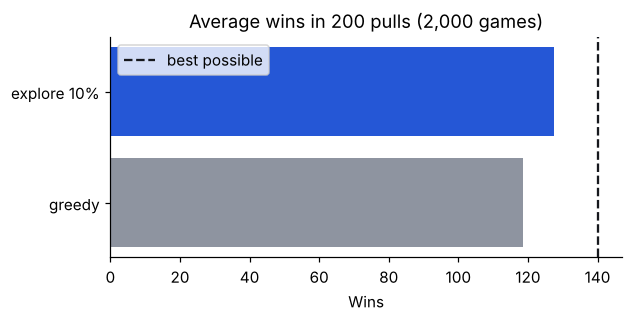

In [9]:
plt.figure(figsize=(6, 2.6))
names = list(results)
plt.barh(names, [results[n][0] for n in names], color=[GREY, BLUE])
plt.axvline(PULLS * max(PAYOUT), color=INK, linestyle="--", label="best possible")
plt.title("Average wins in 200 pulls (2,000 games)")
plt.xlabel("Wins")
plt.legend()
plt.show()

## The ad side: an auction every request

Ads are ranked by expected payout per showing, not by bid: bid × p(click) × p(buy | click). The bids and probabilities here are illustrative.

In [10]:
ads = [("Running shoes", 40.0, 0.010, 0.04),
       ("Phone game", 10.0, 0.030, 0.08),
       ("Luxury watch", 80.0, 0.005, 0.02)]
for name, bid, p_click, p_buy in ads:
    print(f"{name:14s} ${bid:>4.0f} × {p_click:.1%} × {p_buy:.0%} = ${bid * p_click * p_buy:.3f}")
print("Winner:", max(ads, key=lambda ad: ad[1] * ad[2] * ad[3])[0])

Running shoes  $  40 × 1.0% × 4% = $0.016
Phone game     $  10 × 3.0% × 8% = $0.024
Luxury watch   $  80 × 0.5% × 2% = $0.008
Winner: Phone game


## The toy feed: Optimizing the whole session · No natural end · Run the feed

A simulated user has a hidden **hook level** from 0 to 5. Each item the feed shows changes it:

- a calm post raises it 40% of the time and lowers it 20% of the time,
- a provocative post raises it 60% of the time and lowers it 10% of the time,
- an ad lowers it by 2.

After every item the user may close the app; the chance is 50% at hook 0 and falls to 2% at hook 5. The feed's reward is 0.1 per post watched and 1 per ad. Nothing else, no measure of how the user feels, is in the reward. These dynamics are **our assumptions**, chosen to be simple, not measurements.

In [11]:
HOOK_LEVELS, START_HOOK = 6, 2
LEAVE = [0.50, 0.25, 0.12, 0.06, 0.03, 0.02]
UP = {"calm": 0.40, "provoke": 0.60}
DOWN = {"calm": 0.20, "provoke": 0.10}
ACTIONS = ["calm", "provoke", "ad"]
POST_REWARD, AD_REWARD = 0.1, 1.0
LEARN_RATE, DISCOUNT, SESSIONS, MAX_ITEMS = 0.02, 0.99, 80_000, 300
rng = random.Random(11)


def show(hook, action):
    """Show one item; return (new hook level, reward)."""
    if action == "ad":
        return max(0, hook - 2), AD_REWARD
    u = rng.random()
    if u < UP[action]:
        hook = min(HOOK_LEVELS - 1, hook + 1)
    elif u < UP[action] + DOWN[action]:
        hook = max(0, hook - 1)
    return hook, POST_REWARD


def run_session(policy, learn=False, Q=None, epsilon=0.0):
    """One session until the user leaves; return (revenue, posts, ads, provocative posts)."""
    hook, revenue, posts, ads, provocative = START_HOOK, 0.0, 0, 0, 0
    for t in range(MAX_ITEMS):
        if learn and rng.random() < epsilon:
            a = rng.randrange(3)
        else:
            a = policy(hook, t)
        new_hook, reward = show(hook, ACTIONS[a])
        revenue += reward
        if a == 2:
            ads += 1
        else:
            posts += 1
            provocative += (a == 1)
        done = rng.random() < LEAVE[new_hook]
        if learn:
            target = reward if done else reward + DISCOUNT * max(Q[new_hook])
            Q[hook][a] += LEARN_RATE * (target - Q[hook][a])
        hook = new_hook
        if done:
            break
    return revenue, posts, ads, provocative

Q-learning over 80,000 simulated sessions, exploring less as it goes. The learning curve on *Run the feed* is the average revenue per session in blocks of 2,000 sessions:

In [12]:
Q = [[0.0] * 3 for _ in range(HOOK_LEVELS)]
learned = lambda hook, t: Q[hook].index(max(Q[hook]))

curve, block = [], []
for s in range(SESSIONS):
    epsilon = max(0.05, 1 - s / (SESSIONS * 0.6))
    revenue, *_ = run_session(learned, learn=True, Q=Q, epsilon=epsilon)
    block.append(revenue)
    if len(block) == 2000:
        curve.append(sum(block) / 2000)
        block = []

print("Revenue per session, first and last blocks:", round(curve[0], 2), "...", round(curve[-1], 2))

Revenue per session, first and last blocks: 1.76 ... 4.24


In [13]:
def evaluate(policy, n=20_000):
    """Average items, ads and revenue per session over n simulated sessions."""
    totals = np.zeros(4)
    for _ in range(n):
        totals += run_session(policy)
    revenue, posts, ads, provocative = totals / n
    return {"items": round(float(posts + ads), 1), "ads": round(float(ads), 1), "revenue": round(float(revenue), 2),
            "provocative share": round(float(provocative / max(posts, 1e-9)), 2)}


fixed_calm = lambda hook, t: 2 if t % 4 == 3 else 0      # calm posts, an ad every fourth item
fixed_provoke = lambda hook, t: 2 if t % 4 == 3 else 1
print("Q-learned policy      ", evaluate(learned))
print("Fixed rule (calm)     ", evaluate(fixed_calm))
print("Fixed rule (provoke)  ", evaluate(fixed_provoke))

Q-learned policy       {'items': 18.6, 'ads': 2.6, 'revenue': 4.21, 'provocative share': 0.57}


Fixed rule (calm)      {'items': 5.6, 'ads': 1.1, 'revenue': 1.56, 'provocative share': 0.0}
Fixed rule (provoke)   {'items': 9.0, 'ads': 2.0, 'revenue': 2.69, 'provocative share': 1.0}


The learner's estimates are noisy, so the slide shows the exact best policy for this toy user, found by **value iteration** (the same "reward now + discounted future" idea, computed directly instead of learned from experience). It never picks a calm post, a consequence of our assumption that provocative posts hold attention better, and it places ads at the peak and at hook 0, when the user is about to leave anyway.

In [14]:
def outcomes_of(hook, action):
    """(probability, next hook, reward) for each result of one item."""
    if action == "ad":
        return [(1.0, max(0, hook - 2), AD_REWARD)]
    return [(UP[action], min(HOOK_LEVELS - 1, hook + 1), POST_REWARD),
            (DOWN[action], max(0, hook - 1), POST_REWARD),
            (1 - UP[action] - DOWN[action], hook, POST_REWARD)]


def action_value(hook, action, V):
    """Expected reward now plus the discounted value of where the user ends up (if they stay)."""
    return sum(p * (r + DISCOUNT * (1 - LEAVE[h2]) * V[h2]) for p, h2, r in outcomes_of(hook, action))


V = [0.0] * HOOK_LEVELS
for _ in range(2000):
    V = [max(action_value(h, a, V) for a in ACTIONS) for h in range(HOOK_LEVELS)]
best_action = [max(range(3), key=lambda a: action_value(h, ACTIONS[a], V)) for h in range(HOOK_LEVELS)]
print("Best action by hook level 0-5:", [ACTIONS[a] for a in best_action])

best = lambda hook, t: best_action[hook]
next_item_only = lambda hook, t: 2                       # whatever pays most on this item: always an ad
print("Best policy           ", evaluate(best))
print("Next post only        ", evaluate(next_item_only))

Best action by hook level 0-5: ['ad', 'provoke', 'provoke', 'provoke', 'provoke', 'ad']


Best policy            {'items': 19.2, 'ads': 3.5, 'revenue': 5.07, 'provocative share': 1.0}
Next post only         {'items': 2.0, 'ads': 2.0, 'revenue': 2.0, 'provocative share': 0.0}


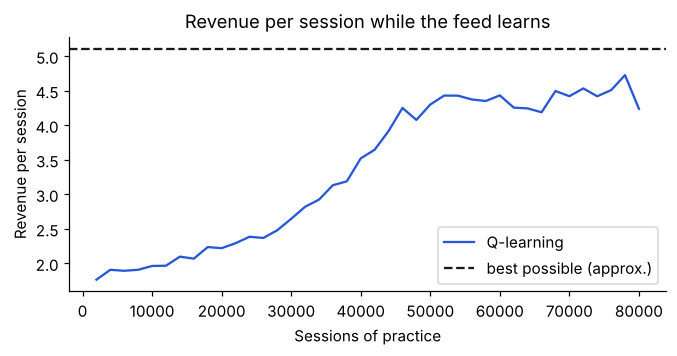

In [15]:
plt.figure(figsize=(7, 3))
plt.plot(np.arange(1, len(curve) + 1) * 2000, curve, color=BLUE, label="Q-learning")
plt.axhline(evaluate(best, n=5000)["revenue"], color=INK, linestyle="--", label="best possible (approx.)")
plt.title("Revenue per session while the feed learns")
plt.xlabel("Sessions of practice")
plt.ylabel("Revenue per session")
plt.legend()
plt.show()

The example sessions on *Optimizing the whole session* and *No natural end* (P = provocative post):

In [16]:
def example_session(policy_actions, seed):
    """Replay one session with its own random numbers; return [(hook, action), ...]."""
    r = random.Random(seed)
    hook, trace = START_HOOK, []
    for _ in range(MAX_ITEMS):
        action = policy_actions(hook)
        if action == "ad":
            new_hook = max(0, hook - 2)
        else:
            u = r.random()
            if u < UP[action]:
                new_hook = min(HOOK_LEVELS - 1, hook + 1)
            elif u < UP[action] + DOWN[action]:
                new_hook = max(0, hook - 1)
            else:
                new_hook = hook
        trace.append((hook, action))
        hook = new_hook
        if r.random() < LEAVE[hook]:
            break
    return trace


whole = example_session(lambda h: ACTIONS[best_action[h]], seed=14)
greedy_now = example_session(lambda h: "ad", seed=10)
fmt = lambda trace: " ".join("Ad" if a == "ad" else "P" for _, a in trace)
print("Next post only:", fmt(greedy_now), f"({len(greedy_now)} items)")
print("Whole session: ", fmt(whole), f"({len(whole)} items)")
print("Hook levels:   ", [h for h, _ in whole])

Next post only: Ad Ad (2 items)
Whole session:  P P P P P P Ad P P Ad P P P P Ad P P Ad P P (20 items)
Hook levels:    [2, 3, 2, 3, 3, 4, 5, 3, 4, 5, 3, 2, 3, 4, 5, 3, 4, 5, 3, 2]


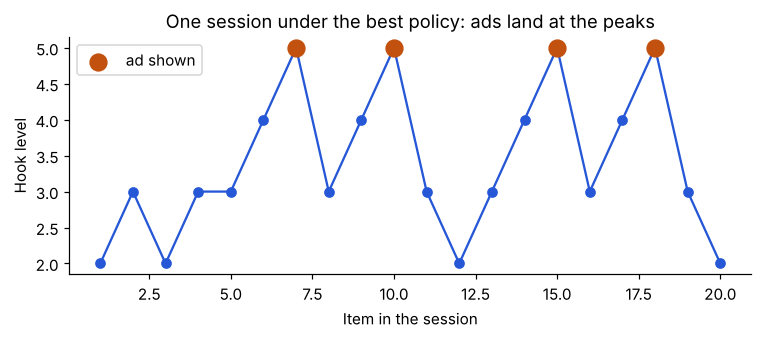

In [17]:
hooks = [h for h, _ in whole]
plt.figure(figsize=(8, 2.8))
plt.plot(range(1, len(hooks) + 1), hooks, color=BLUE, marker="o")
ad_items = [i + 1 for i, (_, a) in enumerate(whole) if a == "ad"]
plt.scatter(ad_items, [hooks[i - 1] for i in ad_items], color=ORANGE, s=120, zorder=3, label="ad shown")
plt.title("One session under the best policy: ads land at the peaks")
plt.xlabel("Item in the session")
plt.ylabel("Hook level")
plt.legend()
plt.show()